# **Análise e Visualização de Dados Sobre o Uso do Pix no Brasil**

O Pix teve seu projeto iniciado em 2018 pelo Banco Central do Brasil (BCB) e foi lançado oficialmente em 2020. Desde então, tem ganhado espaço e popularidade pela sua velociade, praticidade e simplicidade. Após 6 anos de seu funcionamento, decidimos analisar e visualizar seu uso e seu impacto em todo território nacional selecionando uma base de dados oficial no site do Banco Central do Brasil com informações sobre o uso do Pix de Janeiro a Setembro de 2026. Também selecionamos uma base de dados do IBGE de 2022 para complementar nossos dados com, principalmente, a quantidade de habitantes de cada município brasileiro.
Identificamos 6 questões que poderiam ser visualizadas e analisadas:

  1. Mesmo com a popularidade, regiões muito afastadas dos grandes centros urbanos, menos desenvolvidas economicamente, ou com baixa população podem ter uma baixa adesão ao sistema, se comparadas às regiões mais urbanizadas, principalmente pelo acesso a tecnologia mais limitado. Por isso, é importante entender onde o comércio mais fatura com o Pix.
  2. Como se distribui a taxa de adesão ao Pix nas diferentes regiões (Norte, Nordeste, Centro-Oeste, Sudeste, Sul) do Brasil?
  3. É importante entender se existe diferença entre o valor médio do Pix em diferentes cidades.
  4. Quais as cidades que apresentam a maior proporção de empresas a receber via Pix em relação ao número total de habitantes?
  5. É possível identificar cidades em que o valor total recebido pelo comércio local é superior ao valor total das transações feitas pela população?
  6. É possível identificar cidades em que o valor total das transações feitas pela população é superior ao valor total recebido pelo comércio local?

In [1]:
import pandas as pd
import geopandas as gpd
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt

## **Descrição dos Dados**

O seguinte trabalho utiliza duas bases de dados, `dados_pix` e `Populacao_Censo_2022`, ambas em formato CSV. As duas usam o mesmo código de identificação de município (código do IBGE).

A primeira base, **dados_pix**, apresenta dados das transações Pix por município em território nacional, no período de janeiro a setembro de 2026. O dataset possui 50.148 linhas e 19 colunas, onde cada linha representa os dados de um município em um único mês. As colunas são:

- `AnoMes`: mês de referência, no formato 202601 (ano seguido do mês);
- `Municipio_Ibge`: código de identificação do IBGE para cada município;
- `Municipio`: nome do município;
- `Estado_Ibge`: código do IBGE para cada estado;
- `Estado`: nome do estado;
- `Sigla_Regiao`: sigla da região do país (N, NE, SE, S, CO);
- `Regiao`: nome da região do país;
- `VL_PagadorPF`: valor total das transações em que o pagador é pessoa física;
- `QT_PagadorPF`: quantidade de transações em que o pagador é pessoa física;
- `VL_PagadorPJ`: valor total das transações em que o pagador é pessoa jurídica;
- `QT_PagadorPJ`: quantidade de transações em que o pagador é pessoa jurídica;
- `VL_RecebedorPF`: valor total recebido por pessoas físicas;
- `QT_RecebedorPF`: quantidade de transações recebidas por pessoas físicas;
- `VL_RecebedorPJ`: valor total recebido por pessoas jurídicas;
- `QT_RecebedorPJ`: quantidade de transações recebidas por pessoas jurídicas;
- `QT_PES_PagadorPF`: quantidade de pessoas físicas que pagaram via Pix;
- `QT_PES_PagadorPJ`: quantidade de pessoas jurídicas que pagaram via Pix;
- `QT_PES_RecebedorPF`: quantidade de pessoas físicas que receberam via Pix;
- `QT_PES_RecebedorPJ`: quantidade de pessoas jurídicas que receberam via Pix.

Um detalhe importante sobre essa base é que foi encontrado, em cada mês, uma linha sem município informado (`Municipio = N/D`), onde ficam as transações que não puderam ser associadas a nenhuma cidade. Como essas linhas não tem geometria correspondente no shapefile, elas foram desconsideradas na análise espacial. Elas representam cerca de 0,14% do valor e 0,06% da quantidade de transações de pessoas físicas pagadoras, então o efeito sobre os resultados foi ignorado.

A segunda base, **Populacao_Censo_2022**, apresenta dados do ultimo censo do IBGE, em 2022. Por questões de otimização, foram filtradas apenas as colunas de interesse no momento do download do dataset, totalizando 5570 linhas e 3 colunas. Cada linha representa os dados de um município. As colunas são:

- `id_municipio`: código de identificação do IBGE para cada município;
- `id_municipio_nome`: nome do município;
- `populacao_total`: população total residente no município, segundo o Censo 2022.

Para obter os datasets foram utilizados scripts em Python, localizados na pasta `Scripts`. O primeiro, `baixar_censo2022`, consulta a Base dos Dados (biblioteca `basedosdados`), soma a população por município do Censo 2022 e salva o resultado em `Populacao_Censo_2022.csv` (separador `;`, codificação `utf-8-sig`).

O segundo, `converter_pix`, converte para CSV (separador `;`, codificação `utf-8-sig`) a base do Pix baixada manualmente em JSON do portal de dados abertos do Banco Central. O download direto em CSV disponível no portal não foi utilizado porque, ao ser aberto no Excel, apresentou problemas de codificação de caracteres.

OBS.: Os dados da geometria dos municipios para o plot do mapa podem ser baixados em:  https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais/15774-malhas.html  
Base de dados do pix: https://olinda.bcb.gov.br/olinda/servico/Pix_DadosAbertos/versao/v1/aplicacao#!/recursos/EstatisticasTransacoesPix#eyJmb3JtdWxhcmlvIjp7IiRmb3JtYXQiOiJqc29uIiwiJHRvcCI6MTAwfX0=  
Censo do IBGE 2022: https://basedosdados.org/dataset/08a1546e-251f-4546-9fe0-b1e6ab2b203d?table=cf9537b5-6198-455f-a8b0-7c762e94d79c

In [2]:
#Definindo os parametros --------- Nao é IA, eu que to escrevendo comentarios mesmo

arquivo = './dados_pix.csv'
censo_2022 = pd.DataFrame(pd.read_csv('./Populacao_Censo_2022.csv', sep=';'))
tabela_pix = pd.DataFrame(pd.read_csv(arquivo, sep=';'))
mapa = gpd.read_file("zip:./BR_Municipios_2025.zip")

print(tabela_pix.shape)
print(tabela_pix.columns)

c:\Users\leohs\miniconda3\envs\aed20262\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


(50148, 19)
Index(['AnoMes', 'Municipio_Ibge', 'Municipio', 'Estado_Ibge', 'Estado',
       'Sigla_Regiao', 'Regiao', 'VL_PagadorPF', 'QT_PagadorPF',
       'VL_PagadorPJ', 'QT_PagadorPJ', 'VL_RecebedorPF', 'QT_RecebedorPF',
       'VL_RecebedorPJ', 'QT_RecebedorPJ', 'QT_PES_PagadorPF',
       'QT_PES_PagadorPJ', 'QT_PES_RecebedorPF', 'QT_PES_RecebedorPJ'],
      dtype='str')


In [3]:
#Somando os municipios repetidos da tabela
tabela_pix = (
    tabela_pix.groupby("Municipio_Ibge", as_index=False)[
        ["VL_PagadorPF", "VL_PagadorPJ", "QT_PagadorPF", "QT_PagadorPJ", 
        "VL_RecebedorPF","VL_RecebedorPJ", "QT_RecebedorPF", "QT_RecebedorPJ",
        "QT_PES_PagadorPF", "QT_PES_PagadorPJ", "QT_PES_RecebedorPF", "QT_PES_RecebedorPJ"
        ]
    ].sum()
)
print(tabela_pix.shape)
print(tabela_pix.columns)


(5571, 13)
Index(['Municipio_Ibge', 'VL_PagadorPF', 'VL_PagadorPJ', 'QT_PagadorPF',
       'QT_PagadorPJ', 'VL_RecebedorPF', 'VL_RecebedorPJ', 'QT_RecebedorPF',
       'QT_RecebedorPJ', 'QT_PES_PagadorPF', 'QT_PES_PagadorPJ',
       'QT_PES_RecebedorPF', 'QT_PES_RecebedorPJ'],
      dtype='str')


In [4]:
#Criando uma tabela com os valores
# Adicionado ao DataFrame mapa_pix o merge com o censo de 2022
mapa['CD_MUN'] = mapa['CD_MUN'].astype(str)
tabela_pix['Municipio_Ibge'] = tabela_pix['Municipio_Ibge'].fillna(0).astype(int).astype(str)
mapa_pix = pd.merge(mapa, tabela_pix, left_on='CD_MUN', right_on='Municipio_Ibge', how='left')

censo_2022['id_municipio'] = censo_2022['id_municipio'].astype(str)
mapa_pix = pd.merge(mapa_pix, censo_2022, left_on='CD_MUN', right_on='id_municipio', how='left').drop(columns=['id_municipio','id_municipio_nome'])

## **Onde o comércio mais fatura com Pix?**
Aqui fizemos a plotagem do mapa para visualização dos municípios onde o comércio mais fatura com Pix.  
A escala utilizada foi a logaritmica, para conter o efeito causado pelos outliers.

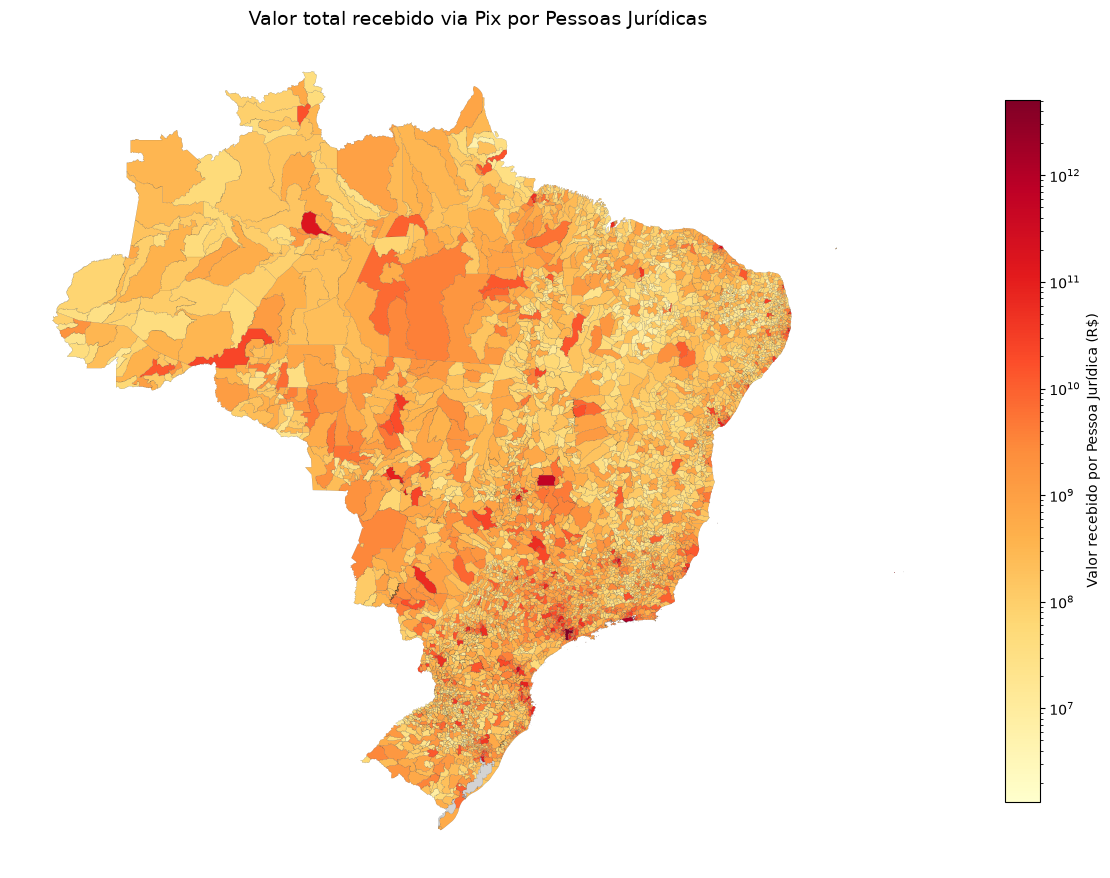

In [5]:
# Define os limites da escala logarítmica
vmin_positivo = max(
    1,
    mapa_pix.loc[
        mapa_pix["VL_RecebedorPJ"] > 0,
        "VL_RecebedorPJ"
    ].min()
)

vmax_valor = mapa_pix["VL_RecebedorPJ"].max()

# Cria um único gráfico
fig, ax = plt.subplots(figsize=(12, 12))

# Desenha o mapa de fundo
mapa.plot(
    ax=ax,
    color="gainsboro",
    edgecolor="white",
    linewidth=0.2
)

# Colore cada município pelo valor recebido por PJ
mapa_pix.plot(
    column="VL_RecebedorPJ",
    cmap="YlOrRd",
    norm=LogNorm(vmin=vmin_positivo, vmax=vmax_valor),
    legend=True,
    legend_kwds={
        "label": "Valor recebido por Pessoa Jurídica (R$)",
        "orientation": "vertical",
        "shrink": 0.6,
    },
    ax=ax,
    edgecolor="black",
    linewidth=0.05,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sem dados"
    },
)

ax.set_title(
    "Valor total recebido via Pix por Pessoas Jurídicas",
    fontsize=14,
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

## **TOP 20 MUNICIPIOS COM MAIS MOVIMENTAÇÃO DE PIX**
Aqui apenas criamos uma tabela com os 20 maiores valores da tabela e criamos uma visualização pintando apenas eles.


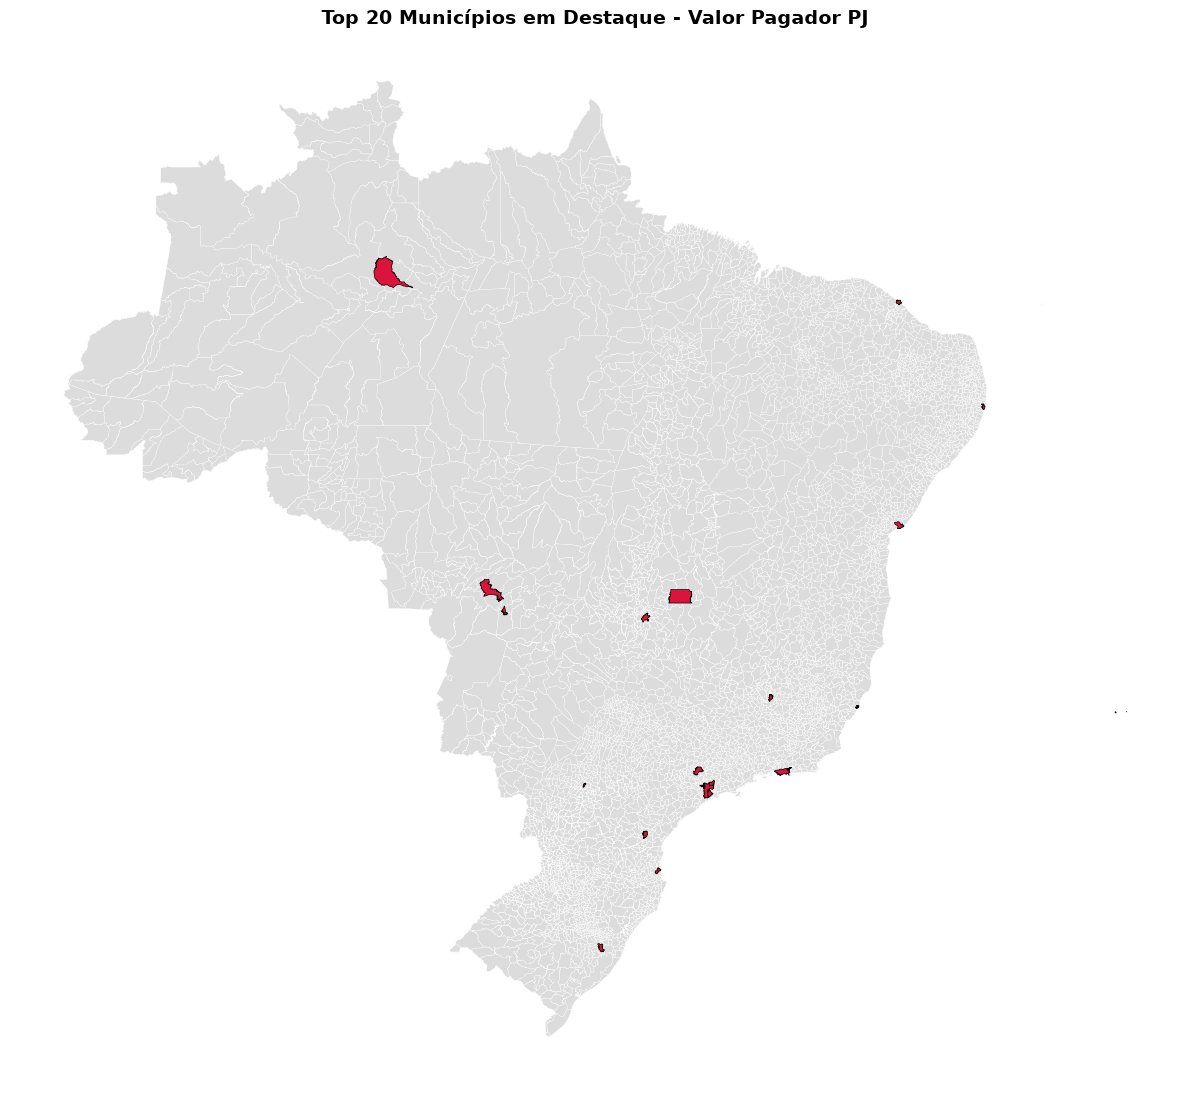

In [ ]:

maiores_20 = maiores.head(20).copy()
maiores_20["Municipio_Ibge"] = (
    maiores_20["Municipio_Ibge"].fillna(0).astype(int).astype(str)
)

maiores_dados = maiores_20.drop(columns=["geometry"], errors="ignore")


mapa["CD_MUN"] = mapa["CD_MUN"].astype(str)
mapa_maiores = mapa.merge(
    maiores_dados, left_on="CD_MUN", right_on="Municipio_Ibge", how="inner"
)


fig, ax = plt.subplots(figsize=(12, 12))

# Camada 1: Todos os municípios do Brasil em cinza (fundo)
mapa.plot(ax=ax, color="gainsboro", edgecolor="white", linewidth=0.2)


mapa_maiores.plot(
    ax=ax, color="crimson", edgecolor="black", linewidth=0.5  # Cor única
)

# Ajustes visuais
ax.set_title(
    "Top 20 Municípios em Destaque - Valor Pagador PJ",
    fontsize=14,
    fontweight="bold",
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

## **Como se distribui a taxa de adesão ao Pix nas diferentes regiões do Brasil?**
Nessa visualiação fizemos a plotagem do mapa para encontrarmos a porcentagem da populações que aderiu ao pix nas diferentes regiões do Brasil. 

<Axes: >

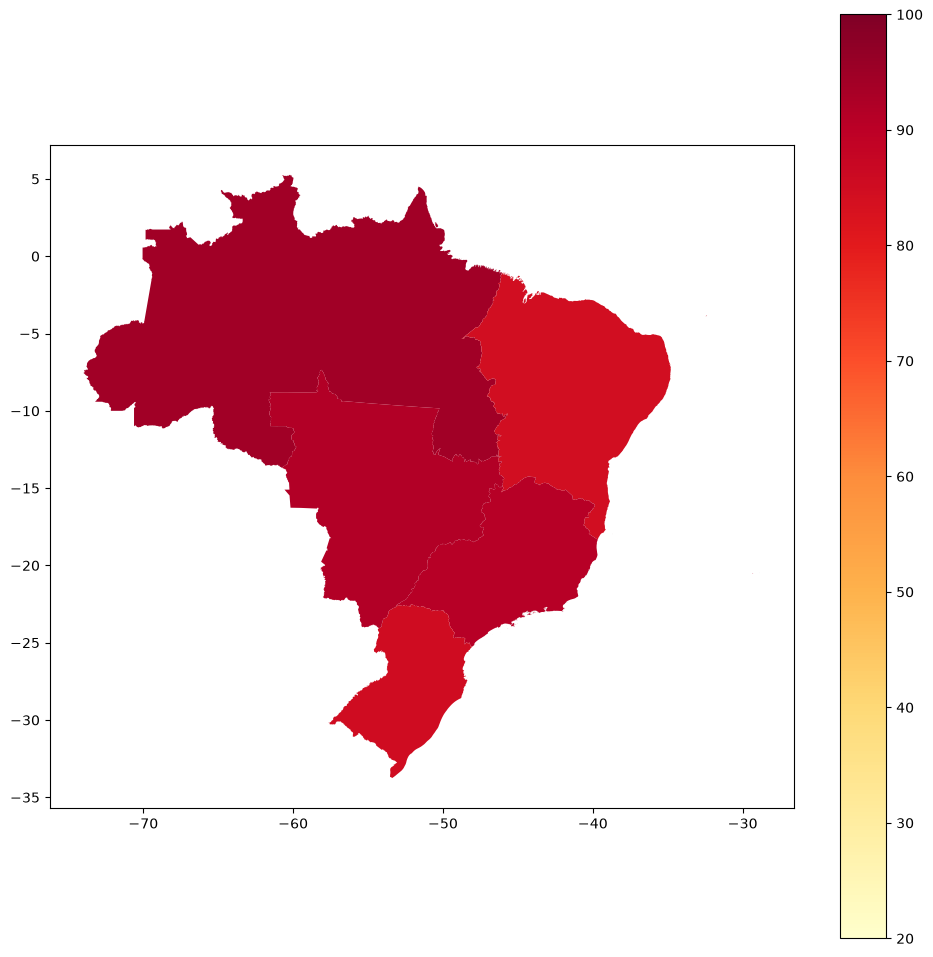

In [6]:
# Foi utilizado a função dissolve no lugar do groupby para poder preservar o formato das figuras

mapa_pix_regioes = mapa_pix.dissolve(by='CD_REGIAO', aggfunc={'QT_PES_PagadorPF' : 'sum', 'populacao_total': 'sum'}).reset_index()

mapa_pix_regioes['QT_PixPorHabitante'] = mapa_pix_regioes['QT_PES_PagadorPF'] / mapa_pix_regioes['populacao_total'] / 9 * 100
 
mapa_pix_regioes.plot(column='QT_PixPorHabitante', legend=True, cmap="YlOrRd", figsize=(12,12), vmin=20, vmax=100)

## **Existe uma correlação entre o tamanho da população e o valor médio das transações feitas por Pix?**
Aqui fizemos um gráfico cujos eixo horizontal representa a população dos municípios em escala logaritmica para conter o efeito dos outliers e o eixo horizontal representa o valor médio por transação dos municípios. Assim plotamos os pontos dos municípios no gráfico.

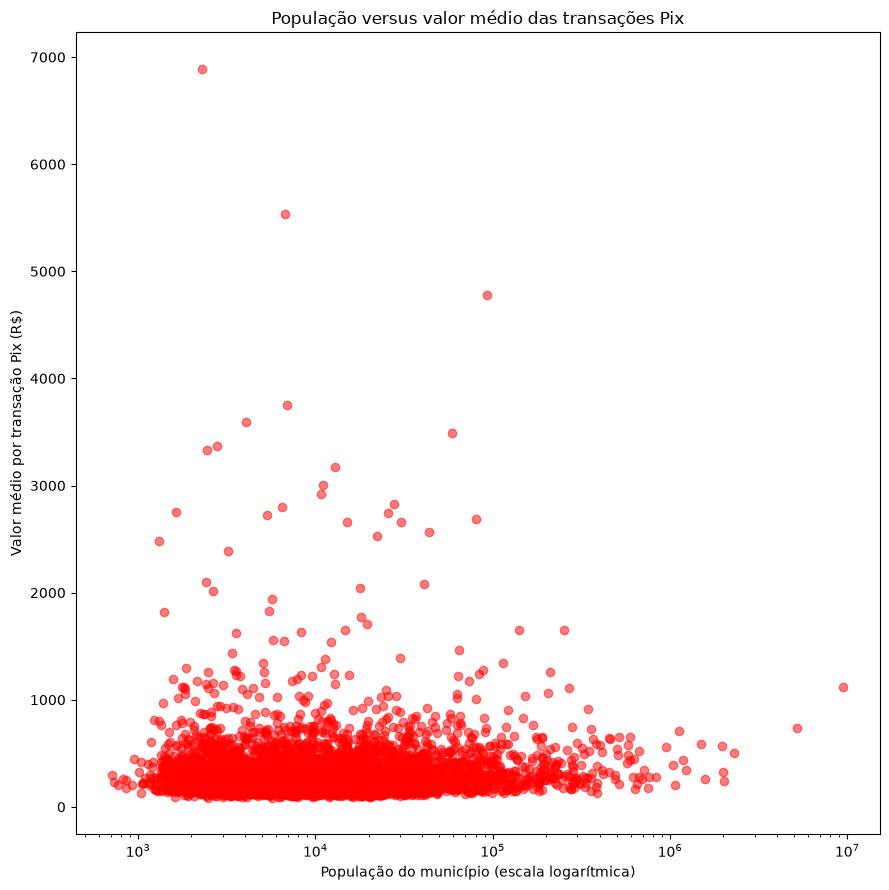

In [7]:
mapa_pix['VL_TotalPagador'] = mapa_pix['VL_PagadorPF'] + mapa_pix['VL_PagadorPJ']
mapa_pix['QT_TotalPagador'] = mapa_pix['QT_PagadorPF'] + mapa_pix['QT_PagadorPJ']
mapa_pix['VL_MedioPago'] = mapa_pix['VL_TotalPagador'] / mapa_pix['QT_TotalPagador']

dados = mapa_pix[
    ["populacao_total", "VL_MedioPago"]
].copy()

dados = dados.apply(pd.to_numeric, errors="coerce")
dados = dados.replace([float("inf"), float("-inf")], float("nan"))
dados = dados.dropna()

# Gráfico de dispersão
plt.figure(figsize=(9, 9))

plt.scatter(
    dados["populacao_total"],
    dados["VL_MedioPago"],
    color="red",
    alpha=0.5
)

plt.xscale("log")
plt.xlabel("População do município (escala logarítmica)")
plt.ylabel("Valor médio por transação Pix (R$)")
plt.title("População versus valor médio das transações Pix")

plt.tight_layout()
plt.show()

In [25]:
maiores = mapa_pix.sort_values("VL_PagadorPJ", ascending=False)
#print(maiores.columns)
maiores[['NM_MUN', 'SIGLA_UF', 'NM_REGIAO', 'VL_PagadorPJ']].head(20)

,NM_MUN,SIGLA_UF,NM_REGIAO,VL_PagadorPJ
502,São Paulo,SP,Sudeste,5.018379e+12
844,Rio de Janeiro,RJ,Sudeste,1.221152e+12
3482,Barueri,SP,Sudeste,4.723683e+11
3341,Curitiba,PR,Sul,3.772821e+11
3112,Belo Horizonte,MG,Sudeste,3.423914e+11
302,Brasília,DF,Centro-oeste,3.389435e+11
520,Porto Alegre,RS,Sul,2.145287e+11
549,Osasco,SP,Sudeste,1.878995e+11
607,Fortaleza,CE,Nordeste,1.787802e+11
1291,Goiânia,GO,Centro-oeste,1.712402e+11


## **CIDADES ONDE A MOVIMENTAÇÃO PF É MAIOR QUE PJ**



In [31]:
PF_maior = mapa_pix[(mapa_pix['VL_PagadorPF'] + mapa_pix['VL_RecebedorPF']) < (mapa_pix['VL_PagadorPJ'] + mapa_pix['VL_RecebedorPJ'])]
PF_maior.head(20)

,CD_MUN,NM_MUN,CD_RGI,NM_RGI,CD_RGINT,NM_RGINT,CD_UF,NM_UF,SIGLA_UF,CD_REGIAO,...,QT_RecebedorPF,QT_RecebedorPJ,QT_PES_PagadorPF,QT_PES_PagadorPJ,QT_PES_RecebedorPF,QT_PES_RecebedorPJ,populacao_total,VL_TotalPagador,QT_TotalPagador,VL_MedioPago
6,4210605,Massaranduba,420016,Joinville,4206,Joinville,42,Santa Catarina,SC,4,...,967290.0,589706.0,87837.0,12926.0,82106.0,12052.0,14039.0,1.398792e+09,2363176.0,591.912030
8,3543402,Ribeirão Preto,350031,Ribeirão Preto,3508,Ribeirão Preto,35,São Paulo,SP,3,...,97819760.0,57338647.0,4775201.0,694187.0,4643919.0,654013.0,580893.0,1.181387e+11,203821810.0,579.617471
9,4120408,Presidente Castelo Branco,410014,Maringá,4104,Maringá,41,Paraná,PR,4,...,482532.0,210075.0,28104.0,2512.0,27460.0,2357.0,3533.0,3.794955e+08,1097019.0,345.933418
14,4128708,Vitorino,410010,Pato Branco,4103,Cascavel,41,Paraná,PR,4,...,653930.0,355711.0,46201.0,6221.0,44228.0,5979.0,7428.0,9.326426e+08,1654622.0,563.658981
21,4308003,Faxinal do Soturno,430011,Santa Maria,4303,Santa Maria,43,Rio Grande do Sul,RS,4,...,532777.0,301956.0,36413.0,3994.0,34721.0,4004.0,5682.0,5.127754e+08,1256193.0,408.197908
23,3102605,Andradas,310051,Poços de Caldas,3109,Pouso Alegre,31,Minas Gerais,MG,3,...,3799069.0,2238750.0,211903.0,21745.0,206705.0,20746.0,33745.0,4.326112e+09,7305616.0,592.162462
24,4202404,Blumenau,420019,Blumenau,4207,Blumenau,42,Santa Catarina,SC,4,...,35092068.0,60367348.0,2497049.0,387982.0,2382708.0,367393.0,300031.0,5.719479e+10,96358885.0,593.560066
43,3510005,Cândido Mota,350014,Assis,3504,Marília,35,São Paulo,SP,3,...,3229994.0,1301519.0,176301.0,15608.0,172542.0,14792.0,24243.0,4.692418e+09,6999922.0,670.352876
47,3110103,Caiana,310034,Carangola,3106,Juíz de Fora,31,Minas Gerais,MG,3,...,364235.0,176091.0,24485.0,1340.0,23724.0,1246.0,4296.0,3.361830e+08,838465.0,400.950588
48,4209904,Lontras,420022,Rio do Sul,4207,Blumenau,42,Santa Catarina,SC,4,...,800053.0,1087456.0,67317.0,10507.0,63800.0,10144.0,10175.0,1.242857e+09,2054661.0,604.896496


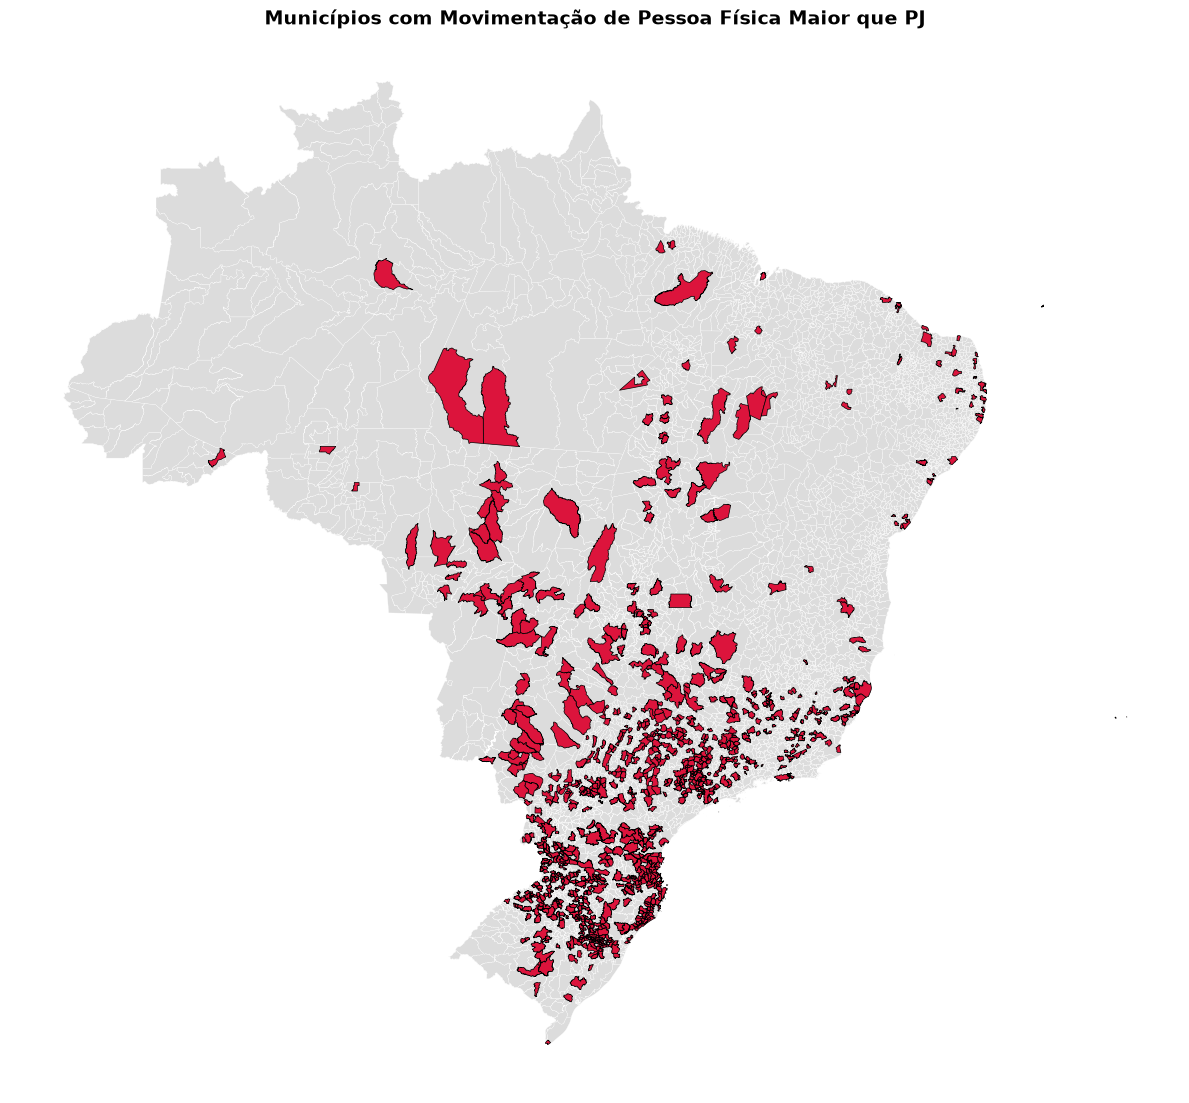

In [ ]:
# 1. Ajusta o tipo da chave no mapa
mapa["CD_MUN"] = mapa["CD_MUN"].astype(str)

# 2. Cria o gráfico
fig, ax = plt.subplots(figsize=(12, 12))

# Camada 1: Todos os municípios do Brasil em cinza (fundo)
mapa.plot(ax=ax, color="gainsboro", edgecolor="white", linewidth=0.2)

# Camada 2: Municípios onde PF > PJ em vermelho
PF_maior.plot(ax=ax, color="crimson", edgecolor="black", linewidth=0.5)

# Ajustes visuais com o título adequado
ax.set_title(
    "Municípios com Movimentação de Pessoa Juridica Maior que Pessoa Fisica",
    fontsize=14,
    fontweight="bold",
)
ax.set_axis_off()

plt.tight_layout()
plt.show()